In [3]:
!pip install -q ultralytics psutil pandas matplotlib

In [4]:
import torch
import psutil
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ultralytics import YOLO
from google.colab import files
from PIL import Image
from IPython.display import display

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [5]:
print("========== SYSTEM INFORMATION ==========")

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

print("CPU Cores:", psutil.cpu_count())
print("CPU Usage:", psutil.cpu_percent(interval=1), "%")

if torch.cuda.is_available():

    print("GPU Name:", torch.cuda.get_device_name(0))

    gpu_memory = torch.cuda.get_device_properties(0).total_memory

    print("GPU Memory:", round(gpu_memory / (1024**3), 2), "GB")

else:

    print("No NVIDIA GPU detected")

print("========================================")

========== SYSTEM INFORMATION ==========
PyTorch Version: 2.14.1+cu130
CUDA Available: True
CPU Cores: 2
CPU Usage: 21.0 %
GPU Name: Tesla T4
GPU Memory: 14.56 GB


In [6]:
if torch.cuda.is_available():
    device = "cuda:0"
else:
    device = "cpu"

print("Selected Device:", device)

model = YOLO("yolo11n.pt")

print("YOLO Model Loaded Successfully!")

Selected Device: cuda:0
YOLO Model Loaded Successfully!


Saving Traffic.jpeg to Traffic.jpeg
Uploaded Image: Traffic.jpeg


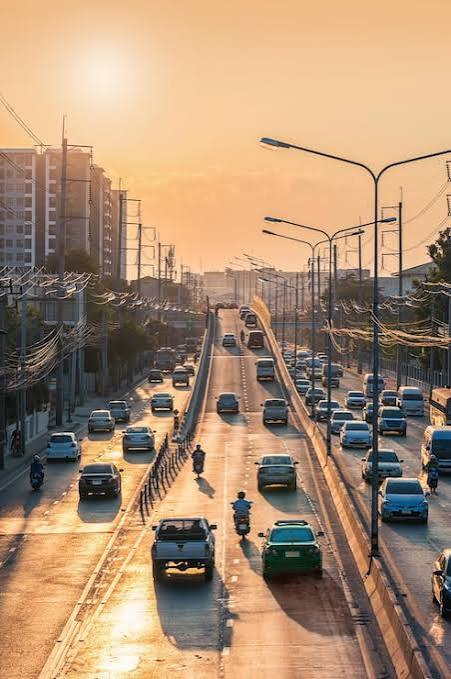

In [7]:
uploaded = files.upload()

image_path = list(uploaded.keys())[0]

image = Image.open(image_path).convert("RGB")

print("Uploaded Image:", image_path)

display(image)

In [8]:
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()

start_time = time.perf_counter()

results = model.predict(
    source=image,
    imgsz=640,
    conf=0.25,
    device=device,
    verbose=False
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

end_time = time.perf_counter()

total_time = (end_time - start_time) * 1000

print("Total Inference Pipeline Time:", round(total_time, 2), "ms")

Total Inference Pipeline Time: 10973.94 ms


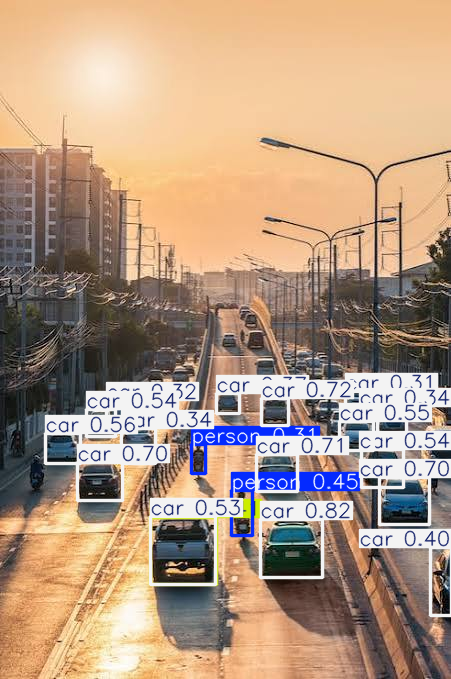

========== DETECTION RESULTS ==========
Total Objects Detected: 19
Object: car | Confidence: 82.23 %
Object: car | Confidence: 71.78 %
Object: car | Confidence: 71.09 %
Object: car | Confidence: 70.32 %
Object: car | Confidence: 69.74 %
Object: car | Confidence: 56.21 %
Object: car | Confidence: 54.82 %
Object: car | Confidence: 54.19 %
Object: car | Confidence: 54.17 %
Object: car | Confidence: 52.88 %
Object: person | Confidence: 45.19 %
Object: truck | Confidence: 40.79 %
Object: car | Confidence: 39.66 %
Object: car | Confidence: 36.96 %
Object: car | Confidence: 34.47 %
Object: car | Confidence: 34.01 %
Object: car | Confidence: 31.83 %
Object: car | Confidence: 31.17 %
Object: person | Confidence: 30.77 %

Object Counts:
car : 16
person : 2
truck : 1


In [9]:
result = results[0]

annotated_image = result.plot()

display(Image.fromarray(annotated_image[:, :, ::-1]))

print("========== DETECTION RESULTS ==========")

print("Total Objects Detected:", len(result.boxes))

object_counts = {}

for box in result.boxes:

    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    object_name = result.names[class_id]

    object_counts[object_name] = object_counts.get(object_name, 0) + 1

    print(
        "Object:", object_name,
        "| Confidence:", round(confidence * 100, 2), "%"
    )

print("\nObject Counts:")

for name, count in object_counts.items():
    print(name, ":", count)

print("=======================================")

In [10]:
speed = result.speed

preprocess_time = speed["preprocess"]
inference_time = speed["inference"]
postprocess_time = speed["postprocess"]

print("========== INFERENCE STAGES ==========")

print("Preprocessing:", round(preprocess_time, 2), "ms")

print("Inference:", round(inference_time, 2), "ms")

print("Postprocessing:", round(postprocess_time, 2), "ms")

print("Total Stage Time:", round(
    preprocess_time + inference_time + postprocess_time, 2
), "ms")

print("======================================")

========== INFERENCE STAGES ==========
Preprocessing: 154.06 ms
Inference: 26.7 ms
Postprocessing: 43.59 ms
Total Stage Time: 224.35 ms


In [11]:
if torch.cuda.is_available():

    allocated = torch.cuda.memory_allocated(0) / (1024**2)

    reserved = torch.cuda.memory_reserved(0) / (1024**2)

    peak_memory = torch.cuda.max_memory_allocated(0) / (1024**2)

    print("========== GPU MEMORY ==========")

    print("Allocated Memory:", round(allocated, 2), "MB")

    print("Reserved Memory:", round(reserved, 2), "MB")

    print("Peak Memory:", round(peak_memory, 2), "MB")

    print("================================")

else:

    print("GPU memory information unavailable because CPU is being used.")

========== GPU MEMORY ==========
Allocated Memory: 52.59 MB
Reserved Memory: 68.0 MB
Peak Memory: 58.48 MB


In [12]:
print("Warming up model...")

for i in range(5):

    model.predict(
        source=image,
        imgsz=640,
        conf=0.25,
        device=device,
        verbose=False
    )

print("Warm-up completed!")

Warming up model...
Warm-up completed!


In [13]:
latencies = []

print("Running 30 inference tests...")

for i in range(30):

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()

    model.predict(
        source=image,
        imgsz=640,
        conf=0.25,
        device=device,
        verbose=False
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    end = time.perf_counter()

    latency = (end - start) * 1000

    latencies.append(latency)

print("Benchmark Completed!")

Running 30 inference tests...
Benchmark Completed!


In [14]:
average_latency = np.mean(latencies)

minimum_latency = np.min(latencies)

maximum_latency = np.max(latencies)

p95_latency = np.percentile(latencies, 95)

throughput = 1000 / average_latency

print("========== PERFORMANCE RESULTS ==========")

print("Average Latency:", round(average_latency, 2), "ms")

print("Minimum Latency:", round(minimum_latency, 2), "ms")

print("Maximum Latency:", round(maximum_latency, 2), "ms")

print("P95 Latency:", round(p95_latency, 2), "ms")

print("Throughput:", round(throughput, 2), "images/second")

print("==========================================")

========== PERFORMANCE RESULTS ==========
Average Latency: 16.69 ms
Minimum Latency: 9.88 ms
Maximum Latency: 55.55 ms
P95 Latency: 38.29 ms
Throughput: 59.91 images/second


In [15]:
stages = {
    "Preprocessing": preprocess_time,
    "Inference": inference_time,
    "Postprocessing": postprocess_time
}

bottleneck = max(stages, key=stages.get)

print("========== BOTTLENECK ANALYSIS ==========")

for stage, duration in stages.items():

    print(stage, ":", round(duration, 2), "ms")

print("\nMain Bottleneck:", bottleneck)

print("=========================================")

========== BOTTLENECK ANALYSIS ==========
Preprocessing : 154.06 ms
Inference : 26.7 ms
Postprocessing : 43.59 ms

Main Bottleneck: Preprocessing


In [16]:
performance_report = pd.DataFrame({
    "Metric": [
        "Preprocessing",
        "Inference",
        "Postprocessing",
        "Average Latency",
        "Minimum Latency",
        "Maximum Latency",
        "P95 Latency",
        "Throughput"
    ],

    "Value": [
        round(preprocess_time, 2),
        round(inference_time, 2),
        round(postprocess_time, 2),
        round(average_latency, 2),
        round(minimum_latency, 2),
        round(maximum_latency, 2),
        round(p95_latency, 2),
        round(throughput, 2)
    ],

    "Unit": [
        "ms", "ms", "ms", "ms", "ms", "ms", "ms", "images/second"
    ]
})

display(performance_report)

,Metric,Value,Unit
0,Preprocessing,154.06,ms
1,Inference,26.70,ms
2,Postprocessing,43.59,ms
3,Average Latency,16.69,ms
4,Minimum Latency,9.88,ms
5,Maximum Latency,55.55,ms
6,P95 Latency,38.29,ms
7,Throughput,59.91,images/second


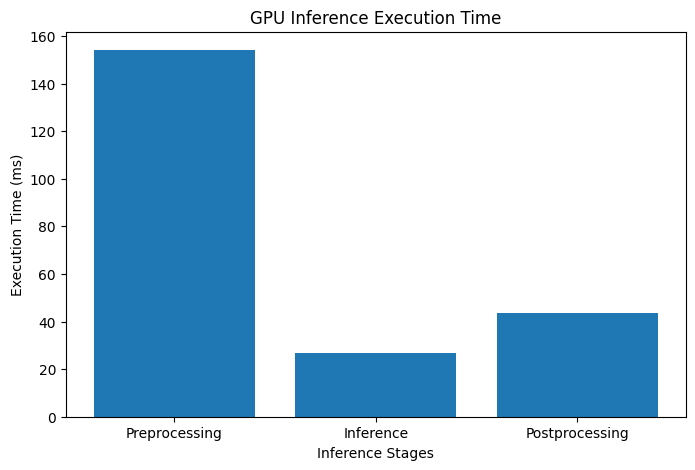

In [17]:
plt.figure(figsize=(8, 5))

plt.bar(stages.keys(), stages.values())

plt.title("GPU Inference Execution Time")

plt.xlabel("Inference Stages")

plt.ylabel("Execution Time (ms)")

plt.show()

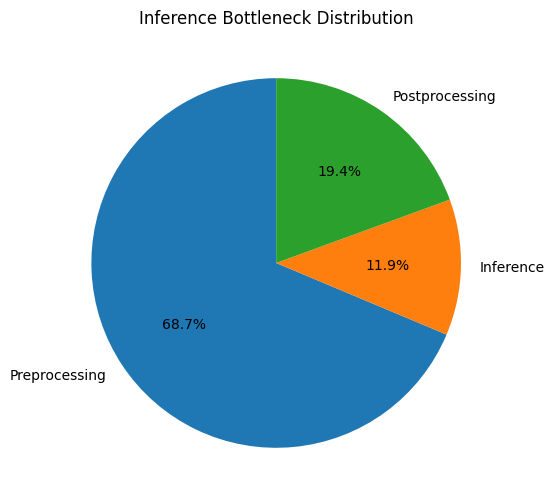

In [18]:
plt.figure(figsize=(6, 6))

plt.pie(
    stages.values(),
    labels=stages.keys(),
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Inference Bottleneck Distribution")

plt.show()